In [1]:
import csv
import json
import math
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FixedLocator, NullLocator
from scipy.linalg import eigh
from scipy.special import gamma, gammaln, kv
from scipy.stats import norm

SEED = 2026102302
DIMENSIONS = (2, 8, 32, 128, 256)
RADII = (0.05, 0.15, 0.5)
CANDIDATE_COUNTS = (32, 64, 128)
N_FIELDS = 10_000
CONFIDENCE_LEVELS = (0.80, 0.90, 0.95, 0.99, 0.999)

PROFILE_SPECS = (
    ("SE", None),
    ("RQ_a1", None),
    ("Matern_3p5", 3.5),
    ("Matern_4p5", 4.5),
)

C3 = 2.0 * math.sqrt(120.0)
FIG_DIR = Path("figs")
RESULTS_DIR = Path("results") / "fixed_input"

for directory in (FIG_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

n_scenarios = len(PROFILE_SPECS) * len(DIMENSIONS) * len(RADII)
print(f"Fixed-input calibration: {n_scenarios} scenarios, "
      f"{N_FIELDS:,} fields per scenario.")
print(f"Seed: {SEED}; finite-set size: {max(CANDIDATE_COUNTS)}")

Fixed-input calibration: 60 scenarios, 10,000 fields per scenario.
Seed: 2026102302; finite-set size: 128


In [2]:
@dataclass(frozen=True)
class Profile:
    name: str
    nu: float | None = None

    def derivative(self, s, order=0):
        """Evaluate the profile derivative with respect to squared distance."""
        s = np.maximum(np.asarray(s, dtype=float), 0.0)

        if self.name == "SE":
            return (-1.0) ** order * np.exp(-s)

        if self.name == "RQ_a1":
            return (-1.0) ** order * math.factorial(order) / (1.0 + s) ** (order + 1)

        nu = self.nu
        assert nu is not None and nu > order
        a = nu - 1.0
        out = np.empty_like(s)

        zero = s == 0
        out[zero] = (-a) ** order * gamma(nu - order) / gamma(nu)
        v = a * s[~zero]
        out[~zero] = (
            (-a) ** order * 2.0 / gamma(nu)
            * v ** ((nu - order) / 2.0) * kv(nu - order, 2.0 * np.sqrt(v))
        )

        return out

    @property
    def gamma3(self):
        return -float(self.derivative(0.0, 3))


PROFILES = tuple(Profile(name, nu) for name, nu in PROFILE_SPECS)

for profile in PROFILES:
    np.testing.assert_allclose(profile.derivative(0.0), 1.0)
    np.testing.assert_allclose(profile.derivative(0.0, 1), -1.0)
    print(f"{profile.name:<12} gamma3 = {profile.gamma3:.6f}")

SE           gamma3 = 1.000000
RQ_a1        gamma3 = 6.000000
Matern_3p5   gamma3 = 8.333333
Matern_4p5   gamma3 = 3.266667


In [3]:
def flip(x):
    """Swap the two D-dimensional input blocks."""
    d = x.shape[-1] // 2
    return np.concatenate((x[..., d:], x[..., :d]), axis=-1)


def squared_distances(x, y):
    return np.maximum(
        np.sum(x * x, axis=1)[:, None]
        + np.sum(y * y, axis=1)[None, :]
        - 2.0 * x @ y.T,
        0.0,
    )


def base_value_taylor(x, y, profile):
    """Covariance of a base field value with the linear and quadratic terms."""
    sx = np.sum(x * x, axis=1)[:, None]
    sy = np.sum(y * y, axis=1)[None, :]
    dot = x @ y.T
    return (
        -2.0 * profile.derivative(sx, 1) * dot
        + profile.derivative(sx, 1) * sy
        + 2.0 * profile.derivative(sx, 2) * dot * dot
    )


def base_taylor_taylor(x, y, profile):
    """Covariance of the base Taylor terms, including the Hessian trace term."""
    sx = np.sum(x * x, axis=1)[:, None]
    sy = np.sum(y * y, axis=1)[None, :]
    dot = x @ y.T
    return (
        -2.0 * profile.derivative(0.0, 1) * dot
        + profile.derivative(0.0, 2) * (sx * sy + 2.0 * dot * dot)
    )


def antisymmetrize(operator, x, y):
    px, py = flip(x), flip(y)
    return operator(x, y) - operator(x, py) - operator(px, y) + operator(px, py)


def joint_field_taylor_covariance(x, profile):
    """Covariance of the stacked field and Taylor values on the same set."""
    ff = antisymmetrize(lambda a, b: profile.derivative(squared_distances(a, b)), x, x)
    ft = antisymmetrize(lambda a, b: base_value_taylor(a, b, profile), x, x)
    tt = antisymmetrize(lambda a, b: base_taylor_taylor(a, b, profile), x, x)
    cov = np.block([[ff, ft], [ft.T, tt]])
    return (cov + cov.T) / 2.0


def reference_error_covariance(x, profile):
    """Closed error covariance used to check the sampling construction."""
    sx = np.sum(x * x, axis=1)
    dot = x @ x.T
    crossed = x @ flip(x).T
    p, q = dot - crossed, dot * dot - crossed * crossed
    return (
        2.0 * (profile.derivative(squared_distances(x, x))
               - profile.derivative(squared_distances(x, flip(x))))
        + 4.0 * (profile.derivative(sx, 1)[:, None]
                 + profile.derivative(sx, 1)[None, :]
                 - profile.derivative(0.0, 1)) * p
        - 4.0 * (profile.derivative(sx, 2)[:, None]
                 + profile.derivative(sx, 2)[None, :]
                 - profile.derivative(0.0, 2)) * q
    )


def reference_error_variance(x, profile):
    """Pointwise error variance used to check the covariance diagonal."""
    d = x.shape[-1] // 2
    a, b = x[:, :d], x[:, d:]
    t = np.sum(x * x, axis=1)
    distance = np.sum((a - b)**2, axis=1)
    q = distance * np.sum((a + b)**2, axis=1)
    return (
        2.0 * (1.0 - profile.derivative(2.0 * distance))
        + 4.0 * (-profile.derivative(0.0, 1) + 2.0 * profile.derivative(t, 1)) * distance
        + 4.0 * (profile.derivative(0.0, 2) - 2.0 * profile.derivative(t, 2)) * q
    )


print("Joint covariance functions ready.")

Joint covariance functions ready.


In [4]:
def candidate_points(dimension, count, rng):
    """Create a field-independent set of boundary, interior, and antidiagonal pairs."""
    directions = rng.normal(size=(count, 2, dimension))
    directions /= np.linalg.norm(directions, axis=2, keepdims=True)

    radii = rng.random(size=(count, 2)) ** (1.0 / dimension)
    points = directions * radii[..., None]

    points[::3] = directions[::3]
    points[1::3, 0] = directions[1::3, 0]
    points[1::3, 1] = -directions[1::3, 0]

    # First pair: (e_1, -e_1).
    points[0] = 0.0
    points[0, 0, 0] = 1.0
    points[0, 1, 0] = -1.0

    return points.reshape(count, 2 * dimension)


def sample_joint_on_points(x, profile, n, rng):
    """Sample n independent fields and return their signed errors on x."""
    cov = joint_field_taylor_covariance(x, profile)
    m = len(x)

    eig, vectors = eigh(cov, driver="evr", check_finite=True)
    scale = max(float(eig[-1]), np.finfo(float).tiny)
    if eig[0] < -1e-10 * scale:
        raise ValueError(f"Materially indefinite joint covariance: {eig[0]=}, {scale=}")

    factor = vectors * np.sqrt(np.maximum(eig, 0.0))[None, :]
    draws = rng.normal(size=(n, 2*m)) @ factor.T

    # The two blocks of each draw come from the same field realization.
    field, taylor = draws[:, :m], draws[:, m:]
    errors = taylor - field

    reconstructed = cov[:m, :m] + cov[m:, m:] - cov[:m, m:] - cov[m:, :m]
    reference = reference_error_covariance(x, profile)
    ref_scale = max(float(np.max(np.abs(reference))), np.finfo(float).tiny)
    relative_error = float(np.max(np.abs(reconstructed - reference)) / ref_scale)
    diagonal = reference_error_variance(x, profile)
    diagonal_error = float(np.max(np.abs(np.diag(reference) - diagonal)) / ref_scale)

    if relative_error > 1e-7 or diagonal_error > 1e-7:
        raise ValueError("Joint covariance disagrees with the reference error formula.")

    flipped = flip(x)
    residual = antisymmetrize(
        lambda a, b: profile.derivative(squared_distances(a, b)), x, flipped
    )
    skew_error = float(np.max(np.abs(residual + cov[:m, :m])))

    diagnostics = {
        "min_eigenvalue": float(eig[0]),
        "largest_eigenvalue": scale,
        "clipped_negative_count": int(np.count_nonzero(eig < 0.0)),
        "error_covariance_relative_error": relative_error,
        "error_diagonal_relative_error": diagonal_error,
        "field_flip_covariance_absolute_error": skew_error,
    }
    return errors, diagnostics


print("Fixed-input sampler ready.")

Fixed-input sampler ready.


In [5]:
def variance_envelope(radius, profile):
    """Return the pointwise variance envelope V_h(R)."""
    r2 = radius * radius
    h1 = float(profile.derivative(0.0, 1))
    h2 = float(profile.derivative(0.0, 2))
    return float(
        2.0 * (1.0 - profile.derivative(8.0 * r2))
        + 16.0 * r2 * max(-h1 + 2.0 * float(profile.derivative(2.0 * r2, 1)), 0.0)
        + 16.0 * r2 * r2 * max(h2 - 2.0 * float(profile.derivative(2.0 * r2, 2)), 0.0)
    )


def scales(radius, dimension, profile):
    """Return the cubic standard-deviation bound and the mean supremum bound."""
    sigma = math.sqrt(2.0) * C3 / 3.0 * math.sqrt(profile.gamma3) * radius**3
    kappa = math.sqrt(2.0) * math.exp(
        gammaln((dimension + 1) / 2.0) - gammaln(dimension / 2.0)
    )
    mean_upper = 2.0 * C3 * kappa * math.sqrt(profile.gamma3) * radius**3
    return sigma, mean_upper


def absolute_thresholds(radius, dimension, profile, p):
    """Thresholds for absolute error at field-confidence level p."""
    sigma, mean_upper = scales(radius, dimension, profile)
    envelope_sd = math.sqrt(variance_envelope(radius, profile))
    z = norm.ppf((1.0 + p) / 2.0)
    return {
        "pointwise_refined": float(z * min(envelope_sd, sigma)),
        "simultaneous": float(
            mean_upper + sigma * math.sqrt(2.0 * math.log(1.0 / (1.0 - p)))
        ),
    }


def wilson_interval(successes, n):
    """Return the 95% Wilson interval for an empirical coverage."""
    z = norm.ppf(0.975)
    coverage = successes / n
    denominator = 1.0 + z * z / n
    center = (coverage + z * z / (2.0 * n)) / denominator
    half = z * math.sqrt(
        coverage * (1.0 - coverage) / n + z * z / (4.0 * n * n)
    ) / denominator
    return float(max(0.0, center - half)), float(min(1.0, center + half))


CALIBRATION_EVENTS = {
    "pointwise_refined": "absolute_error_at_fixed_reference_point",
    "simultaneous": "maximum_on_128_fixed_points",
}


def calibration_record(values, threshold, profile, dimension, radius, p, scheme):
    """Summarize the absolute errors or the finite-set maxima for one bound."""
    n = len(values)
    successes = int(np.count_nonzero(values <= threshold))
    low, high = wilson_interval(successes, n)
    quantile = float(np.quantile(values, p, method="linear"))

    exact_coverage = None
    if scheme == "pointwise_refined":
        x_ref = np.zeros((1, 2 * dimension))
        x_ref[0, 0], x_ref[0, dimension] = radius, -radius
        variance = float(reference_error_variance(x_ref, profile)[0])
        exact_coverage = float(2.0 * norm.cdf(threshold / math.sqrt(variance)) - 1.0)

    return {
        "profile": profile.name,
        "dimension": int(dimension),
        "radius": float(radius),
        "p": float(p),
        "scheme": scheme,
        "event": CALIBRATION_EVENTS[scheme],
        "n": n,
        "successes": successes,
        "failures": n - successes,
        "coverage": successes / n,
        "coverage_wilson95_low": low,
        "coverage_wilson95_high": high,
        "threshold": threshold,
        "empirical_quantile": quantile,
        "threshold_over_empirical_quantile": threshold / quantile,
        "exact_gaussian_fixed_point_coverage": exact_coverage,
        "measured_continuum_supremum_coverage": False,
    }


print("Threshold and coverage functions ready.")

Threshold and coverage functions ready.


In [8]:
RUN_NEW_SIMULATION = True
REFERENCE_PATH = Path("data") / "CALIBRATION_DATA.json"


def run_fixed_input_calibration():
    """Repeat the fixed-input experiment using the original seed schedule."""
    raw_dir = RESULTS_DIR / "raw"
    raw_dir.mkdir(parents=True, exist_ok=True)

    seed_sequence = np.random.SeedSequence(SEED)
    records = []
    diagnostics = []

    for dimension in DIMENSIONS:
        point_rng = np.random.default_rng(seed_sequence.spawn(1)[0])
        unit_points = candidate_points(dimension, max(CANDIDATE_COUNTS), point_rng)
        np.save(raw_dir / f"unit_points_D{dimension}.npy", unit_points)

        for profile in PROFILES:
            for radius in RADII:
                # Keep the original seed schedule, including the child
                # reserved for the pilot's independent random inputs.
                field_seed, _ = seed_sequence.spawn(2)
                field_rng = np.random.default_rng(field_seed)
                errors, diag = sample_joint_on_points(
                    radius * unit_points, profile, N_FIELDS, field_rng
                )

                absolute = np.abs(errors)
                maxima = np.column_stack([
                    absolute[:, :count].max(axis=1) for count in CANDIDATE_COUNTS
                ])
                tag = f"{profile.name}_D{dimension}_R{radius:g}"
                np.savez_compressed(
                    raw_dir / f"{tag}.npz",
                    fixed_reference_point_errors=errors[:, 0],
                    finite_set_maxima=maxima,
                )

                values = {
                    "pointwise_refined": absolute[:, 0],
                    "simultaneous": maxima[:, -1],
                }
                for p in CONFIDENCE_LEVELS:
                    thresholds = absolute_thresholds(radius, dimension, profile, p)
                    for scheme in CALIBRATION_EVENTS:
                        records.append(calibration_record(
                            values[scheme], thresholds[scheme], profile,
                            dimension, radius, p, scheme
                        ))

                diagnostics.append(dict(
                    profile=profile.name, dimension=dimension, radius=radius, **diag
                ))

    (RESULTS_DIR / "rerun_diagnostics.json").write_text(
        json.dumps(diagnostics, indent=2) + "\n", encoding="utf-8"
    )
    return records


if RUN_NEW_SIMULATION:
    CALIBRATION_RECORDS = run_fixed_input_calibration()
    calibration_source = "New simulation"
else:
    if not REFERENCE_PATH.is_file():
        raise FileNotFoundError(
            f"Place CALIBRATION_DATA.json at {REFERENCE_PATH.resolve()} "
            "or set RUN_NEW_SIMULATION = True."
        )
    CALIBRATION_RECORDS = json.loads(REFERENCE_PATH.read_text(encoding="utf-8"))
    calibration_source = "Archived calibration"

expected_keys = {
    (profile.name, dimension, radius, p, scheme)
    for profile in PROFILES
    for dimension in DIMENSIONS
    for radius in RADII
    for p in CONFIDENCE_LEVELS
    for scheme in CALIBRATION_EVENTS
}
actual_keys = {
    (row["profile"], row["dimension"], row["radius"], row["p"], row["scheme"])
    for row in CALIBRATION_RECORDS
}
if (actual_keys != expected_keys
        or len(CALIBRATION_RECORDS) != len(expected_keys)
        or any(row["n"] != N_FIELDS for row in CALIBRATION_RECORDS)):
    raise ValueError("Calibration data do not match the experiment settings.")

if RUN_NEW_SIMULATION:
    (RESULTS_DIR / "calibration_rerun.json").write_text(
        json.dumps(CALIBRATION_RECORDS, indent=2) + "\n", encoding="utf-8"
    )

print(f"{calibration_source}: {len(CALIBRATION_RECORDS)} records.")

New simulation: 600 records.


In [9]:
PROFILE_LABELS = {
    "SE": ("SE", "SE"),
    "RQ_a1": ("RQ", "RQ"),
    "Matern_3p5": ("Matérn 7/2", r"Mat\'ern $7/2$"),
    "Matern_4p5": ("Matérn 9/2", r"Mat\'ern $9/2$"),
}

coverage_index = {
    (row["profile"], row["dimension"], row["radius"], row["p"], row["scheme"]):
        row["coverage"]
    for row in CALIBRATION_RECORDS
}

pointwise_percent = {
    (profile.name, d, r, p):
        f"{100 * coverage_index[profile.name, d, r, p, 'pointwise_refined']:.2f}"
    for profile in PROFILES
    for d in DIMENSIONS
    for r in RADII
    for p in CONFIDENCE_LEVELS
}
column_widths = {
    p: max(len(value) for key, value in pointwise_percent.items() if key[-1] == p)
    for p in CONFIDENCE_LEVELS
}

header = ["Profile", "D"] + [f"p={100*p:g}%" for p in CONFIDENCE_LEVELS]
table1_rows = []
tex_rows = []

for i, profile in enumerate(PROFILES):
    label, tex_label = PROFILE_LABELS[profile.name]
    for j, d in enumerate(DIMENSIONS):
        values = [
            [pointwise_percent[profile.name, d, r, p] for r in RADII]
            for p in CONFIDENCE_LEVELS
        ]
        table1_rows.append([label, str(d)] + ["/".join(triple) for triple in values])

        tex_values = [
            "/".join(r"\phantom{0}" * (column_widths[p] - len(value)) + value
                     for value in triple)
            for p, triple in zip(CONFIDENCE_LEVELS, values)
        ]
        tex_cells = [tex_label if j == 0 else "", str(d)] + tex_values
        space = "[3pt]" if j == len(DIMENSIONS) - 1 and i < len(PROFILES) - 1 else ""
        tex_rows.append(" & ".join(tex_cells) + r" \\" + space)

sim_ranges = []
for p in CONFIDENCE_LEVELS:
    coverages = [
        coverage_index[profile.name, d, r, p, "simultaneous"]
        for profile in PROFILES for d in DIMENSIONS for r in RADII
    ]
    sim_ranges.append((min(coverages), max(coverages)))


def format_sim_range(low, high, separator):
    return (f"{100*low:.2f}" if low == high
            else f"{100*low:.2f}{separator}{100*high:.2f}")


table1_rows.append(
    ["Simultaneous", ""] + [format_sim_range(lo, hi, "-") for lo, hi in sim_ranges]
)
sim_tex = [format_sim_range(lo, hi, "--") for lo, hi in sim_ranges]

if all(lo == hi for lo, hi in sim_ranges):
    sim_note = (
        "The last row gives the identical coverages observed\n"
        "in every scenario for the simultaneous threshold on the 128-point\n"
        "set; samples are not pooled."
    )
else:
    sim_note = (
        "The last row gives the range of coverages across scenarios for the\n"
        "simultaneous threshold on the 128-point set. A single value is shown\n"
        "when all scenarios agree; samples are not pooled."
    )

radius_order = "/".join(f"{r:g}" for r in RADII)
caption = (
    r"\caption{Empirical coverage (\%) from "
    + f"{N_FIELDS:,} independent fields per\n"
    + "scenario. Columns give the nominal field-confidence levels. In each\n"
    + f"pointwise cell, the three values correspond to $R={radius_order}$,\n"
    + "in that order. " + sim_note + " RQ has $a=1$.}"
)
tex_header = ["Profile", "$D$"] + [
    rf"\multicolumn{{1}}{{c}}{{$p={100*p:g}\%$}}" for p in CONFIDENCE_LEVELS
]
tex_lines = [
    r"\begin{table}[pos=htbp]",
    r"\centering\small",
    r"\setlength{\tabcolsep}{2.1pt}",
    r"\renewcommand{\arraystretch}{1.08}",
    r"\setlength{\aboverulesep}{0pt}",
    r"\setlength{\belowrulesep}{0pt}",
    r"\setlength{\extrarowheight}{1pt}",
    caption,
    r"\label{tab:empirical-calibration}",
    r"\begin{tabular}{@{}l|l|rrrrr@{}}",
    r"\toprule",
    " & ".join(tex_header) + r" \\",
    r"\midrule",
    *tex_rows,
    r"\midrule",
    "Simultaneous & & " + " & ".join(sim_tex) + r" \\",
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]

table1_tex = RESULTS_DIR / "table1_coverage.tex"
table1_csv = RESULTS_DIR / "table1_coverage.csv"
table1_tex.write_text("\n".join(tex_lines) + "\n", encoding="utf-8")
with table1_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow(header)
    writer.writerows(table1_rows)

widths = [max(map(len, column)) for column in zip(header, *table1_rows)]
for row in [header, *table1_rows]:
    print(" | ".join(value.ljust(width) for value, width in zip(row, widths)))

print(f"\nSaved: {table1_tex}\nSaved: {table1_csv}")

Profile      | D   | p=80%             | p=90%             | p=95%             | p=99%             | p=99.9%            
SE           | 2   | 81.20/81.86/92.06 | 90.28/90.94/97.60 | 95.36/95.44/99.43 | 99.13/99.25/99.97 | 99.95/99.92/100.00 
SE           | 8   | 80.24/81.54/91.88 | 90.28/91.18/97.35 | 95.08/95.63/99.17 | 98.93/99.20/99.96 | 99.92/99.95/100.00 
SE           | 32  | 80.11/81.37/92.46 | 90.07/90.58/97.58 | 94.96/95.57/99.35 | 99.08/99.29/99.98 | 99.89/99.91/100.00 
SE           | 128 | 80.08/81.10/92.00 | 90.04/90.88/97.54 | 94.81/95.62/99.45 | 99.01/99.28/99.97 | 99.95/99.91/100.00 
SE           | 256 | 79.53/80.55/92.24 | 89.84/90.79/97.68 | 95.13/95.57/99.30 | 99.10/99.11/99.96 | 99.90/99.90/100.00 
RQ           | 2   | 80.69/84.23/87.60 | 90.23/92.91/95.31 | 95.17/96.84/98.02 | 99.01/99.49/99.86 | 99.87/99.98/99.99  
RQ           | 8   | 80.52/84.81/87.79 | 90.35/93.26/95.16 | 95.35/97.22/98.27 | 99.05/99.66/99.73 | 99.90/99.99/100.00 
RQ           | 32  | 80.03/85.02

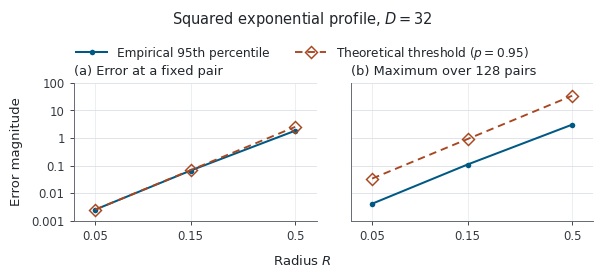

Threshold / empirical 95th percentile:
R=0.05: pointwise 1.00; simultaneous 8.18
R=0.15: pointwise 1.03; simultaneous 8.38
R=0.5: pointwise 1.38; simultaneous 11.15

Saved: figs/calibration_p95.pdf
Saved: figs/calibration_p95.png
Saved: results/fixed_input/figure6_calibration_p95.csv


In [10]:
figure6_radii = list(RADII)
figure6_panels = (
    ("pointwise_refined", "(a) Error at a fixed pair"),
    ("simultaneous", "(b) Maximum over 128 pairs"),
)

figure6_data = {
    (row["scheme"], row["radius"]): row
    for row in CALIBRATION_RECORDS
    if (row["profile"], row["dimension"], row["p"]) == ("SE", 32, 0.95)
}

figure6_pdf = FIG_DIR / "calibration_p95.pdf"
figure6_png = FIG_DIR / "calibration_p95.png"
figure6_csv = RESULTS_DIR / "figure6_calibration_p95.csv"

figure6_style = {
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42,
    "text.color": "#20262c",
    "axes.labelcolor": "#20262c",
    "axes.edgecolor": "#646b73",
    "axes.linewidth": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": "#343a40",
    "ytick.color": "#343a40",
    "xtick.labelsize": 8.4,
    "ytick.labelsize": 8.4,
    "figure.facecolor": "white",
}

with plt.rc_context(figure6_style):
    fig6, axes = plt.subplots(1, 2, figsize=(6.10, 2.78), sharex=True, sharey=True)
    fig6.subplots_adjust(left=0.125, right=0.977, bottom=0.218,
                         top=0.714, wspace=0.14)
    fig6.suptitle("Squared exponential profile, " + r"$D=32$", y=0.977, fontsize=10.5)
    fig6.supxlabel(r"Radius $R$", y=0.048, fontsize=9.5)
    axes[0].set_ylabel("Error magnitude", fontsize=9.5, labelpad=6)

    for ax, (scheme, title) in zip(axes, figure6_panels):
        subset = [figure6_data[scheme, r] for r in figure6_radii]

        empirical, = ax.plot(
            figure6_radii, [row["empirical_quantile"] for row in subset],
            color="#005984", linewidth=1.45, marker="o", markersize=4.0,
            markeredgewidth=0, zorder=3, label="Empirical 95th percentile",
        )
        threshold, = ax.plot(
            figure6_radii, [row["threshold"] for row in subset],
            color="#a84620", linewidth=1.35, linestyle=(0, (4, 2.6)),
            marker="D", markersize=5.9, markerfacecolor="none",
            markeredgewidth=1.05, zorder=4, label=r"Theoretical threshold ($p=0.95$)",
        )

        ax.set_title(title, loc="left", fontsize=9.4, pad=6)
        ax.set(xscale="log", yscale="log", xlim=(0.039, 0.64), ylim=(0.001, 100))
        ax.set_xticks(figure6_radii, [f"{r:g}" for r in figure6_radii])
        ax.yaxis.set_major_locator(FixedLocator([0.001, 0.01, 0.1, 1, 10, 100]))
        ax.set_yticklabels(["0.001", "0.01", "0.1", "1", "10", "100"])
        ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_minor_locator(NullLocator())
        ax.tick_params(which="major", length=3, width=0.65)
        ax.grid(axis="y", color="#d9dee3", linewidth=0.55)
        ax.grid(axis="x", color="#e7ebef", linewidth=0.55)
        ax.set_axisbelow(True)

    axes[1].tick_params(axis="y", left=False, labelleft=False)
    fig6.legend(
        [empirical, threshold], [empirical.get_label(), threshold.get_label()],
        loc="upper center", bbox_to_anchor=(0.5, 0.892), frameon=False,
        ncols=2, fontsize=8.7, handlelength=2.6, columnspacing=2.1,
    )
    fig6.savefig(figure6_pdf, metadata={
        "Title": "Fixed-input Monte Carlo calibration at 95%",
        "Subject": "Squared exponential profile, D=32",
        "CreationDate": None,
    })
    fig6.savefig(figure6_png, dpi=260)
    plt.show()
    plt.close(fig6)

with figure6_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(
        stream,
        fieldnames=["profile", "dimension", "p", "scheme", "radius", "n",
                    "coverage", "threshold", "empirical_quantile",
                    "threshold_over_empirical_quantile"],
        extrasaction="ignore",
    )
    writer.writeheader()
    writer.writerows(
        figure6_data[scheme, r] for scheme, _ in figure6_panels for r in figure6_radii
    )

print("Threshold / empirical 95th percentile:")
for r in figure6_radii:
    pw_ratio = figure6_data["pointwise_refined", r]["threshold_over_empirical_quantile"]
    sim_ratio = figure6_data["simultaneous", r]["threshold_over_empirical_quantile"]
    print(f"R={r:g}: pointwise {pw_ratio:.2f}; simultaneous {sim_ratio:.2f}")

print(f"\nSaved: {figure6_pdf}\nSaved: {figure6_png}\nSaved: {figure6_csv}")